# Imports

In [44]:
import pandas as pd
pd.set_option('display.max_columns', None)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.stats import norm
from statsmodels.stats.proportion import proportions_ztest


# Part A: Organize the Data

A.1 Building the deliveries dataframe

In [6]:
#Enter the match_id

match_id = "1473502"
filename = f"{match_id}.csv"
df = pd.read_csv(filename)
print(df.head(2))

   match_id  season  start_date                             venue  innings  \
0   1473502    2025  2025-05-22  Narendra Modi Stadium, Ahmedabad        1   
1   1473502    2025  2025-05-22  Narendra Modi Stadium, Ahmedabad        1   

   ball          batting_team    bowling_team     striker non_striker  \
0   0.1  Lucknow Super Giants  Gujarat Titans  AK Markram    MR Marsh   
1   0.2  Lucknow Super Giants  Gujarat Titans  AK Markram    MR Marsh   

           bowler  runs_off_bat  extras  wides  noballs  byes  legbyes  \
0  Mohammed Siraj             4       0    NaN      NaN   NaN      NaN   
1  Mohammed Siraj             0       0    NaN      NaN   NaN      NaN   

   penalty wicket_type player_dismissed  other_wicket_type  \
0      NaN         NaN              NaN                NaN   
1      NaN         NaN              NaN                NaN   

   other_player_dismissed  
0                     NaN  
1                     NaN  


In [10]:
#Data cleaning

clean_df = df.copy()

# 1. Extract over from ball 
clean_df["over"] = np.floor(clean_df["ball"]).astype(int)

# 2. Total runs 
clean_df["total_runs"] = clean_df["runs_off_bat"] + clean_df["extras"]

# 3. Wicket indicator
clean_df["wicket_flag"] = clean_df["player_dismissed"].notna().astype(int)

# 4. Phase of match
def get_phase(over):
    if over <= 5:
        return "powerplay"
    elif over <= 15:
        return "middle"
    else:
        return "death"

clean_df["phase"] = clean_df["over"].apply(get_phase)

# ---- 5. Select required columns ----
clean_df = clean_df[
    [
        "match_id",
        "innings",
        "ball",
        "over",
        "batting_team",
        "bowling_team",
        "striker",
        "non_striker",
        "bowler",
        "runs_off_bat",
        "extras",
        "total_runs",
        "wicket_flag",
        "phase",
    ]
]

clean_df.head(2)

,match_id,innings,ball,over,batting_team,bowling_team,striker,non_striker,bowler,runs_off_bat,extras,total_runs,wicket_flag,phase
0,1473502,1,0.1,0,Lucknow Super Giants,Gujarat Titans,AK Markram,MR Marsh,Mohammed Siraj,4,0,4,0,powerplay
1,1473502,1,0.2,0,Lucknow Super Giants,Gujarat Titans,AK Markram,MR Marsh,Mohammed Siraj,0,0,0,0,powerplay


A.2 Building the match_info dataset

In [15]:
#making match_info dictionary from the match_info csv

match_info_filename =  f"{match_id}_info.csv"

match_info = {
    "date": None,
    "venue": None,
    "teams": [],
    "toss_winner": None,
    "toss_decision": None,
    "winner": None,
    "players": {}
}

with open(match_info_filename) as f:
    for line in f:
        parts = line.strip().split(",")

        if parts[0] != "info":
            continue

        key = parts[1]

        if key == "dates":
            match_info["date"] = parts[2]

        elif key == "venue":
            match_info["venue"] = ",".join(parts[2:]).strip()

        elif key == "team":
            match_info["teams"].append(parts[2])

        elif key == "toss_winner":
            match_info["toss_winner"] = parts[2]

        elif key == "toss_decision":
            match_info["toss_decision"] = parts[2]

        elif key == "winner":
            match_info["winner"] = parts[2]

        elif key == "player":
            team = parts[2]
            player = parts[3]

            if team not in match_info["players"]:
                match_info["players"][team] = []

            match_info["players"][team].append(player)

print(match_info)

{'date': None, 'venue': '"Narendra Modi Stadium, Ahmedabad"', 'teams': ['Lucknow Super Giants', 'Gujarat Titans'], 'toss_winner': 'Gujarat Titans', 'toss_decision': 'field', 'winner': 'Lucknow Super Giants', 'players': {'Lucknow Super Giants': ['AK Markram', 'MR Marsh', 'N Pooran', 'RR Pant', 'A Badoni', 'Abdul Samad', 'Himmat Singh', 'Shahbaz Ahmed', 'Avesh Khan', 'Akash Deep', "W O'Rourke", 'Akash Singh'], 'Gujarat Titans': ['B Sai Sudharsan', 'Shubman Gill', 'JC Buttler', 'SE Rutherford', 'M Shahrukh Khan', 'R Tewatia', 'Arshad Khan', 'Rashid Khan', 'K Rabada', 'R Sai Kishore', 'Mohammed Siraj', 'M Prasidh Krishna']}}


# Part B: EDA for Power Play

In [19]:
powerplay_df = clean_df[clean_df["phase"] == "powerplay"]
non_powerplay_df = clean_df[clean_df["phase"] != "powerplay"].copy()
print (powerplay_df.head(2))

   match_id  innings  ball  over          batting_team    bowling_team  \
0   1473502        1   0.1     0  Lucknow Super Giants  Gujarat Titans   
1   1473502        1   0.2     0  Lucknow Super Giants  Gujarat Titans   

      striker non_striker          bowler  runs_off_bat  extras  total_runs  \
0  AK Markram    MR Marsh  Mohammed Siraj             4       0           4   
1  AK Markram    MR Marsh  Mohammed Siraj             0       0           0   

   wicket_flag      phase  
0            0  powerplay  
1            0  powerplay  


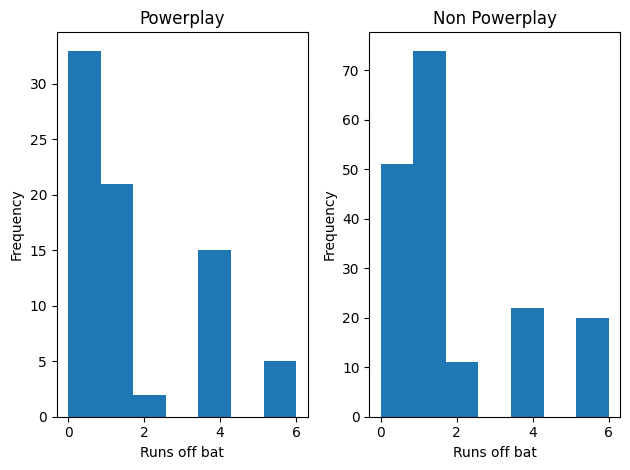

In [20]:
#Historam of runs_off_bat

plt.figure()

# Powerplay histogram
plt.subplot(1, 2, 1)
plt.hist(powerplay_df["runs_off_bat"], bins=7)
plt.xlabel("Runs off bat")
plt.ylabel("Frequency")
plt.title("Powerplay")

# Non-powerplay histogram
plt.subplot(1, 2, 2)
plt.hist(non_powerplay_df["runs_off_bat"], bins=7)
plt.xlabel("Runs off bat")
plt.ylabel("Frequency")
plt.title("Non Powerplay")

plt.tight_layout()
plt.show()

From the above plot, it is clear that the boudnary percentage is higher during the power play

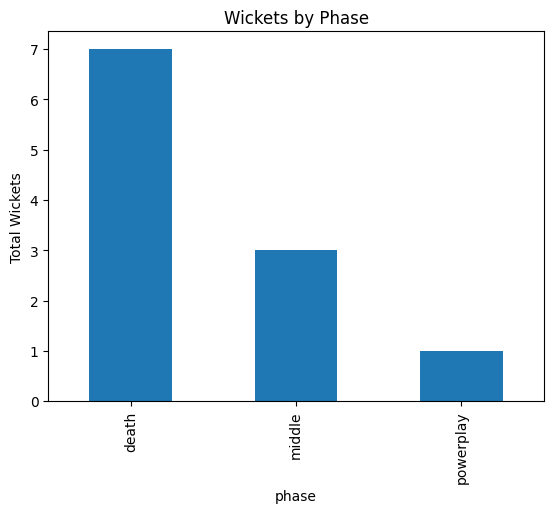

In [22]:
wickets_phase = clean_df.groupby("phase")["wicket_flag"].sum()

wickets_phase.plot(kind="bar")
plt.ylabel("Total Wickets")
plt.title("Wickets by Phase")
plt.show()

The above plot depicts how players take risks in the death overs as the innings is coming to an end

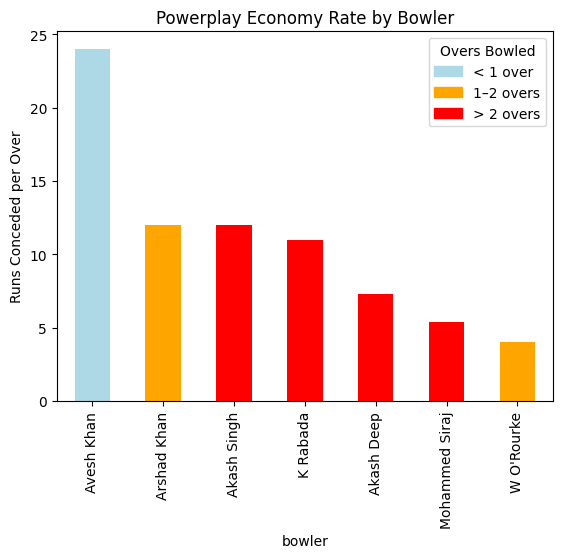

In [26]:
# total runs conceded
runs_conceded = powerplay_df.groupby("bowler")["total_runs"].sum()

# balls bowled
balls_bowled = powerplay_df.groupby("bowler").size()

# overs bowled
overs_bowled = balls_bowled / 6

# economy
runs_per_over = runs_conceded / overs_bowled

# combine into dataframe
bowler_stats = runs_per_over.to_frame("economy")
bowler_stats["overs"] = overs_bowled

# top 10 by economy
bowler_stats = bowler_stats.sort_values("economy", ascending=False).head(10)

# color based on overs bowled
def get_color(o):
    if o < 1:
        return "lightblue"
    elif o < 2:
        return "orange"
    else:
        return "red"

colors = bowler_stats["overs"].apply(get_color)

# plot
bowler_stats["economy"].plot(kind="bar", color=colors)

plt.ylabel("Runs Conceded per Over")
plt.title("Powerplay Economy Rate by Bowler")

# legend
legend_elements = [
    mpatches.Patch(color="lightblue", label="< 1 over"),
    mpatches.Patch(color="orange", label="1–2 overs"),
    mpatches.Patch(color="red", label="> 2 overs")
]

plt.legend(handles=legend_elements, title="Overs Bowled")

plt.show()

The above plot shows quality of bowlers in the power play

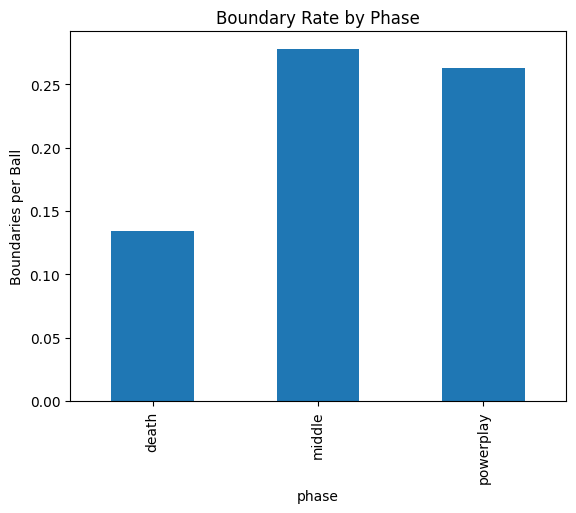

In [27]:
# identify boundaries
boundaries = clean_df[clean_df["runs_off_bat"].isin([4,6])]

# boundaries per phase
boundary_counts = boundaries.groupby("phase").size()

# total balls per phase
balls_per_phase = clean_df.groupby("phase").size()

# boundary rate
boundary_rate = boundary_counts / balls_per_phase

# plot
boundary_rate.plot(kind="bar")

plt.ylabel("Boundaries per Ball")
plt.title("Boundary Rate by Phase")
plt.show()

Power play has a high boundaries per delivery ratio and surprisingly the ratio is higher for the middle overs

# Part C: Making a cricketing decision 

### One-sided two-proportion z-test

**Setup**

Two independent samples:

- Sample 1: $n_1$ trials, $x_1$ successes  
  $\hat p_1 = \frac{x_1}{n_1}$

- Sample 2: $n_2$ trials, $x_2$ successes  
  $\hat p_2 = \frac{x_2}{n_2}$

---

**Hypotheses**

$$
H_0: p_1 = p_2
$$

$$
H_1: p_1 > p_2
$$

---

**Pooled proportion (under $H_0$)**

$$
\hat p = \frac{x_1 + x_2}{n_1 + n_2}
$$

---

**Test statistic**

$$
Z =
\frac{\hat p_1 - \hat p_2}
{\sqrt{\hat p(1-\hat p)\left(\frac{1}{n_1}+\frac{1}{n_2}\right)}}
$$

---

**Distribution under $H_0$**

$$
Z \sim N(0,1)
$$

---

**Rejection rule**

Reject $H_0$ if

$$
Z > z_\alpha
$$

where

$$
z_\alpha = \Phi^{-1}(1-\alpha)
$$

---

**P-value**

For observed statistic $z$:

$$
p\text{-value} = P(Z \ge z) = 1 - \Phi(z)
$$

Reject $H_0$ if

$$
p\text{-value} < \alpha
$$

Test 1: Boundary rate comparison

In [33]:
#Creating clean_df_2 which includes the wides column

clean_df_2 = df.copy()

# 1. Extract over from ball
clean_df_2["over"] = np.floor(clean_df_2["ball"]).astype(int)

# 2. Total runs
clean_df_2["total_runs"] = clean_df_2["runs_off_bat"] + clean_df_2["extras"]

# 3. Wicket indicator
clean_df_2["wicket_flag"] = clean_df_2["player_dismissed"].notna().astype(int)

# 4. Phase of match
def get_phase(over):
    if over <= 5:
        return "powerplay"
    elif over <= 15:
        return "middle"
    else:
        return "death"

clean_df_2["phase"] = clean_df_2["over"].apply(get_phase)

# 5. Select required columns (including wides)
clean_df_2 = clean_df_2[
    [
        "match_id",
        "innings",
        "ball",
        "over",
        "batting_team",
        "bowling_team",
        "striker",
        "non_striker",
        "bowler",
        "runs_off_bat",
        "extras",
        "wides",          # <-- added
        "total_runs",
        "wicket_flag",
        "phase",
    ]
]

clean_df_2.head(2)

,match_id,innings,ball,over,batting_team,bowling_team,striker,non_striker,bowler,runs_off_bat,extras,wides,total_runs,wicket_flag,phase
0,1473502,1,0.1,0,Lucknow Super Giants,Gujarat Titans,AK Markram,MR Marsh,Mohammed Siraj,4,0,NaN,4,0,powerplay
1,1473502,1,0.2,0,Lucknow Super Giants,Gujarat Titans,AK Markram,MR Marsh,Mohammed Siraj,0,0,NaN,0,0,powerplay


In [34]:
#Creating a new powerplay df which includes the wides column

powerplay_df2 = clean_df_2[clean_df_2["phase"] == "powerplay"].copy()

Selecting the team and batsman to compare

In [35]:
team_selected = "Lucknow Super Giants"

# get only rows where this team is batting
team_powerplay = powerplay_df2[powerplay_df2["batting_team"] == team_selected]

# first two batsmen (from striker column order)
batsmen = team_powerplay["striker"].drop_duplicates().head(2).tolist()

batsman_1 = batsmen[0]
batsman_2 = batsmen[1]

print("Batsman 1:", batsman_1)
print("Batsman 2:", batsman_2)


# function to compute stats
def batsman_stats(df, batsman):
    
    # balls faced (exclude wides)
    balls = (
        (df["striker"] == batsman) &
        (df["wides"]!=1)
    ).sum()
    
    boundaries = (
        ((df["striker"] == batsman) & (df["runs_off_bat"].isin([4,6]))).sum()
    )
    
    return balls, boundaries


balls_1, boundaries_1 = batsman_stats(team_powerplay, batsman_1)
balls_2, boundaries_2 = batsman_stats(team_powerplay, batsman_2)


print("\nStats in Powerplay:")
print(f"{batsman_1}: {balls_1} balls faced, {boundaries_1} boundaries")
print(f"{batsman_2}: {balls_2} balls faced, {boundaries_2} boundaries")

Batsman 1: AK Markram
Batsman 2: MR Marsh

Stats in Powerplay:
AK Markram: 17 balls faced, 4 boundaries
MR Marsh: 19 balls faced, 3 boundaries


Computing test statistic and p value

In [37]:
# sample proportions
p1_hat = boundaries_1 / balls_1
p2_hat = boundaries_2 / balls_2

# pooled proportion
p_hat = (boundaries_1 + boundaries_2) / (balls_1 + balls_2)

# test statistic
z = (p1_hat - p2_hat) / np.sqrt(p_hat*(1-p_hat)*(1/balls_1 + 1/balls_2))

# p-value (one-sided)
p_value = 1 - norm.cdf(z)

print("\nTwo-Proportion Test")
print("z statistic:", z)
print("p-value:", p_value)


Two-Proportion Test
z statistic: 0.5857900341930483
p-value: 0.27900831080732624


effective size


In [40]:
# effect size
effect_size = p1_hat - p2_hat
print("Effect size (p1_hat - p2_hat):", effect_size)

Effect size (p1_hat - p2_hat): 0.07739938080495357


Using the imported test to calculate directly

In [45]:
count = np.array([boundaries_1, boundaries_2])
nobs = np.array([balls_1, balls_2])
stat, pval = proportions_ztest(count, nobs, alternative = 'larger')
print("Test statistic (z): {0:0.3f}".format(stat))
print("p-value: {0:0.3f}".format(pval))

Test statistic (z): 0.586
p-value: 0.279
